## Dynamics of observed molecular evolution 

## 0. General

### 0.1. load libraries

In [1]:

import pandas as pd, numpy as np, json
from Bio import SeqIO
from Bio.Seq import Seq



In [2]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.gridspec as gridspec

import seaborn as sns

sns.set_theme(style="white", font="Arial")
sns.set_context({'font.size': 10.0, 'axes.labelsize': 12, 'axes.titlesize': 14,
                 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
                 'legend.title_fontsize': None, 'axes.linewidth': 0.8, 'grid.linewidth': 0.8,
                 'lines.linewidth': 1.5, 'lines.markersize': 6.0, 'patch.linewidth': 1.0,
                 'xtick.major.width': 0.5, 'ytick.major.width': 0.5, 'xtick.minor.width': 0.3,
                 'ytick.minor.width': 0.3, 'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
                 'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,})

plt.rcParams['xtick.bottom'] = True
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['font.size'] = 12
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True


### 0.2. General variables

In [3]:
donors = [1,2,3,4]
replicates = ["A", "B", "C"]
passages = list(range(0, 110, 10))
tech_reps = [1,2 ]
populations = ["1A", "1B", "1C", "2A", "2B", "2C", "3A", "3B", "3C", "4A", "4B", "4C"]
segments = ["1-PB2", "2-PB1", "3-PA", "4-HA", "5-NP", "6-NA", "7-M", "8-NS"]

hours_per_passage = 72 #hours
generation_time = 6 #hours > assumption based on Baccam, et al. 2006

In [4]:
segment_nuc_cds = {r.id:r.seq for r in SeqIO.parse('../data/references/stock_consensus_cds.fasta', 'fasta')}
with open('../data/CDS_H3N2.json') as json_file:
    coding_json = json.load(json_file)
    
aapos2codon = {}
nucpos2aapos = {}
for segment, pdict in coding_json.items():
    aapos2codon[segment] = {}
    nucpos2aapos[segment] = {}
    for protein, posdict in pdict.items():
        aapos2codon[segment][protein] = {}
        
        for aapos in np.arange(1, posdict["pro_aa_pos"][-1]+1):
            nucpos = [posdict["nuc_cds_pos"][i] for i, aap in enumerate(posdict["pro_aa_pos"]) if aap == aapos]
            aapos2codon[segment][protein][aapos] = nucpos
    
        nucpos2aapos[segment][protein] = {nucpos:posdict["pro_aa_pos"][i] for i, nucpos in enumerate(posdict["nuc_cds_pos"])}


In [5]:
#color palette 
population_cpal = [ "#005fb9", "#58b4e2", "#8ee6ff", "#860041", "#ca0090", "#ff53c0", "#006e00", "#77a908", "#bbe837", "#0000ba", "#5f38ed", "#d49eff" ]
segment_cpal = ["#ea5545","#f46a9b", "#ef9b20", "#ede15b", "#87bc45", "#27aeef", "#776efa", "#b33dc6"]

nonsyn_color = "#d90368"
syn_color = "#fb8b24"


### 0.3. Functions 

In [6]:
def score_codon_position(codon, position, target_AA):
  
    score = 0
    for b in ["A", "C", "T", "G"]:
        if b == codon[position]: continue
        
        #determine if mutation was a transition or a transversion and assign weight
        weight = weight_Tn if f'{codon[position]}{b}' in ["AG", "GA", "CT", "TC"] else weight_Tv
        
        
        mutated_codon = codon[:position] + b + codon[position+1:]
        aa = mutated_codon.translate()
        if aa == target_AA:
            score += weight/3.0 #division by 3 for single codon fraction

    return score



def score_codon_for_stops(codon):
    return sum(score_codon_position(codon, i, "*") for i in range(3))

def count_stop_codon_sites(codons):
    return sum(score_codon_for_stops(codon) for codon in codons)

def score_codon_for_syn(codon):
    return sum(score_codon_position(codon, i, codon.translate()) for i in range(3))

def count_syn_codon_sites(codons):
    return sum(score_codon_for_syn(codon) for codon in codons) 

## 1. Total derived allele frequency
Total derived Allele frequency is defined as $M_{p}(t) = \sum f_{p,m}(t)$, for all mutations $m$ in population $p$ at time $t$, as defined by [Good, et al. 2017](https://www.nature.com/articles/nature24287)
 

In [7]:
TnTv = 3
weight_Tn = 3 * TnTv / (1 + TnTv)
weight_Tv = (3 - weight_Tn) / 2


available_sites_per_gene = {}
for segment, sdict in coding_json.items():
    available_sites_per_gene[segment] = {}
    for gene, gdict in sdict.items():
        available_sites_per_gene[segment][gene] = {}
        
        #for each gene get the coding sequence
        gene_seq = Seq("".join([b for i,b in enumerate(segment_nuc_cds[segment]) if i+1 in gdict['nuc_cds_pos']]))
        
        #split seq into codons
        gene_codons = [gene_seq[i:i+3] for i in range(0, len(gene_seq), 3)]
        
        #get number of available sites per mutation type
        stop_sites = count_stop_codon_sites(gene_codons)
        syn_sites = count_syn_codon_sites(gene_codons)
        ns_sites = len(gene_seq) - syn_sites
        
        available_sites_per_gene[segment][gene]["stop"] = stop_sites
        available_sites_per_gene[segment][gene]["syn"] = syn_sites
        available_sites_per_gene[segment][gene]["ns"] = ns_sites
        


In [8]:
overlapping_nucpos = {}
for segment, sdict in nucpos2aapos.items():
    if len (sdict.keys()) == 1:
        overlapping_nucpos[segment] = []
        
        continue
    
    seen_positions = []
    overlapping_pos = []
    for protein, ndict in sdict.items():
        for nucpos in ndict.keys():
            if nucpos not in seen_positions:
                seen_positions.append(nucpos)
            else:
                overlapping_pos.append(nucpos)
                
    
    overlapping_nucpos[segment] = overlapping_pos

In [9]:
available_sites_per_segment = {}
for segment, sdict in coding_json.items():
    available_sites_per_segment[segment] = {}
    
    if len(sdict.keys())==1:
        gene = list(sdict.keys())[0]
        
        #for each gene get the coding sequence
        gene_seq = Seq("".join([b for i,b in enumerate(segment_nuc_cds[segment]) if i+1 in gdict['nuc_cds_pos']]))
        
        #split seq into codons
        gene_codons = [gene_seq[i:i+3] for i in range(0, len(gene_seq), 3)]
        
        #get number of available sites per mutation type
        stop_sites = count_stop_codon_sites(gene_codons)
        syn_sites = count_syn_codon_sites(gene_codons)
        ns_sites = len(gene_seq) - syn_sites
        
        available_sites_per_segment[segment]["stop"] = stop_sites
        available_sites_per_segment[segment]["syn"] = syn_sites
        available_sites_per_segment[segment]["ns"] = ns_sites
      
    #this only work with two overlapping reading frames > great for flu anymore I did not even consider  
    else:
        gene1, gene2 = list(sdict.keys())
        
        
        stop_sites, syn_sites, ns_sites = 0,0,0
        seen_nucs = [] #this should in the end hold all the positions of the segment cds
        for aapos, nucposlist in aapos2codon[segment][gene1].items():
            #here we can just determine the number of availabe nucleotide for the code 
            codon = Seq("".join([segment_nuc_cds[segment][nucpos-1] for nucpos in nucposlist]))
            if not any(nucpos in overlapping_nucpos[segment] for nucpos in nucposlist):
                stops = count_stop_codon_sites([codon])
                syns = count_syn_codon_sites([codon])
                nss = 3 - syns
                
                stop_sites += stops
                syn_sites += syns
                ns_sites += nss 

            else:
                #determine for each individual nucleotide position the nu
                for i, nucpos in enumerate(nucposlist):
                    if nucpos not in overlapping_nucpos[segment]:
                        stops = score_codon_position(codon, i, "*")
                        syns = score_codon_position(codon, i, codon.translate())
                        nss = 1-syns
                        
                    else:
                        alternative_codon_position = [altnp for altnp in aapos2codon[segment][gene2].values() if nucpos in altnp][0]
                        alternative_codon = Seq("".join([segment_nuc_cds[segment][altnp-1] for altnp in alternative_codon_position]))
                        alt_npi = alternative_codon_position.index(nucpos)
                        
                        #for base change determine if mutation results in stop or ns change either data frame 
                        stops, syns =  0, 0 
                        for base in ["A", "T", "C", "G"]:
                            weight = weight_Tn if f'{codon[i]}{base}' in ["AG", "GA", "CT", "TC"] else weight_Tv
                            mut1 = codon[:i] + base + codon[i+1:]
                            aa1 = mut1.translate()
                            
                            mut2 = alternative_codon[:alt_npi] + base + alternative_codon[alt_npi+1:]
                            aa2 = mut2.translate()
                            
                            if aa1 == "*" or aa2=="*":
                                stops += weight/3
                                nss += weight/3
                                
                                
                            elif aa1 == codon.translate() and aa2 == alternative_codon.translate():
                                syns += weight/3
                        
                        nss = 1- syns    
                            
                    
                    stop_sites += stops
                    syn_sites += syns
                    ns_sites += nss 

            seen_nucs.extend(nucposlist)

        #repeating for the non overlapping positions of           
        for aapos, nucposlist in aapos2codon[segment][gene2].items():
            #here we can just determine the number of availabe nucleotide for the code 
            codon = Seq("".join([segment_nuc_cds[segment][nucpos-1] for nucpos in nucposlist]))
            if not any(nucpos in overlapping_nucpos[segment] for nucpos in nucposlist):
                if any(nucpos in seen_nucs for nucpos in nucposlist):
                    print ("bug")
                stops = count_stop_codon_sites([codon])
                syns = count_syn_codon_sites([codon])
                nss = 3 - syns
                
                stop_sites += stops
                syn_sites += syns
                ns_sites += nss 
                
                seen_nucs.extend(nucposlist)
                    
            else:
                #determine for each individual nucleotide position the nu
                for i, nucpos in enumerate(nucposlist):
                    if nucpos not in overlapping_nucpos[segment]:
                        stops = score_codon_position(codon, i, "*")
                        syns = score_codon_position(codon, i, codon.translate())
                        nss = 1-syns
                        
                        stop_sites += stops
                        syn_sites += syns
                        ns_sites += nss 
                        
                        seen_nucs.append(nucpos)
        
        # if sum([syn_sites, ns_sites]) != len(segment_nuc_cds[segment]):
        #     print (f"number of available sites does not match segment length for {segment}")
        #     print (sum([syn_sites, ns_sites]), len(segment_nuc_cds[segment]))
            
            
        # for nucpos  in [i for i in range(1, len(segment_nuc_cds[segment])+1) if i not in seen_nucs]:
        #     print (nucpos)
                
        available_sites_per_segment[segment]["stop"] = stop_sites
        available_sites_per_segment[segment]["syn"] = syn_sites
        available_sites_per_segment[segment]["ns"] = ns_sites
        
                
       
 

In [10]:
#load data
#load snv summary 
snv_summary = pd.read_csv("../results/snv_summary.csv").set_index(["population", "refname", "nucpos", "snv"]).sort_index()

#create overview of non-synonymous SNVs (for convienence)
non_synonymous_dict = {segment:[] for segment in segments}
for i in snv_summary[snv_summary["non_synonymous"]==True].index.droplevel(0):
    non_synonymous_dict[i[0]].append(i[-1])
    
#load trajectories 
trajectories = pd.read_csv("../results/snv_trajectories.csv").set_index(["population", "refname", "nucpos", "snv"]).sort_index()
trajectories = trajectories.rename(columns={c:int(c) for c in trajectories.columns})

In [11]:
accumulative_frequency = []
for population in populations:
    donor, replicate = int(population[0]), population[-1]
    df = trajectories.loc[population, :].dropna(axis=1)
    #get non-synomynous 
    ns_idx = []
    for (segment, npos, snv) in df.index.unique():
        if snv in non_synonymous_dict[segment]:
            ns_idx.append((segment, npos, snv))

    ndf = df[df.index.isin(ns_idx)]
    sdf = df[~df.index.isin(ns_idx)]
    
    for passage in df.columns:
        acf = sum(df[passage])
        ns_acf = sum(ndf[passage])
        syn_acf = sum(sdf[passage])


        accumulative_frequency.append([population, passage, 'genome', acf, ns_acf, syn_acf])

        for segment in segments:
            if segment in df.index.get_level_values(0):
                acf = sum(df.loc[segment][passage])
            else:
                acf = 0 
            
            if segment in ndf.index.get_level_values(0):
                ns_acf = sum(ndf.loc[segment][passage])
            else:
                ns_acf = 0
                
            if segment in sdf.index.get_level_values(0):
                
                syn_acf = sum(sdf.loc[segment][passage])
            else:
                syn_acf = 0
                
            accumulative_frequency.append([population, passage, segment, acf, ns_acf, syn_acf])
                  
accumulative_frequency = pd.DataFrame.from_records(accumulative_frequency, columns=["population", "passage", "refname", "accumulative freq","accumulative nonsyn freq", "accumulative syn freq"])

### 1.1. Accumulation per population by substitution type

Text(-14, 0, 'SNVs, M(t)')

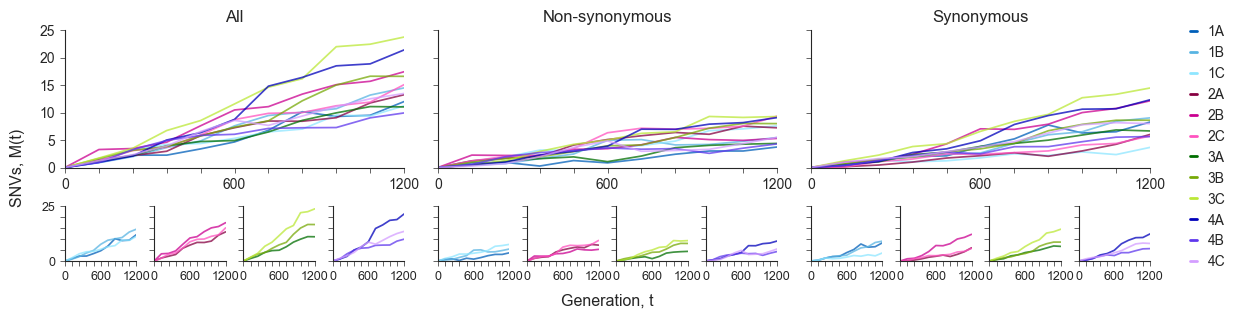

In [12]:
fig = plt.figure(figsize=(14,3))

gs = gridspec.GridSpec(2,1, wspace=0.25, hspace=0.4, height_ratios=[2.5,1])
gsi = gridspec.GridSpecFromSubplotSpec(1,3, subplot_spec=gs[0], hspace=0.3, wspace=0.1)

all_ax = fig.add_subplot(gsi[0])
nonsyn_ax = fig.add_subplot(gsi[1])
syn_ax = fig.add_subplot(gsi[2])

population_legend_elements = []
for i, population in enumerate(populations):
    population_legend_elements.append(Line2D([0], [0], color=population_cpal[i], label=population, linewidth=2,  ))


gsi = gridspec.GridSpecFromSubplotSpec(1,3, subplot_spec=gs[1], hspace=0.3, wspace=0.1)
gsij = gridspec.GridSpecFromSubplotSpec(1,4, subplot_spec=gsi[0], hspace=0.3, wspace=0.25)
donor_all_axes = [fig.add_subplot(gsij[0]), fig.add_subplot(gsij[1]), fig.add_subplot(gsij[2]), fig.add_subplot(gsij[3])]
gsij = gridspec.GridSpecFromSubplotSpec(1,4, subplot_spec=gsi[1], hspace=0.3, wspace=0.25)
donor_nonsyn_axes = [fig.add_subplot(gsij[0]), fig.add_subplot(gsij[1]), fig.add_subplot(gsij[2]), fig.add_subplot(gsij[3])]
gsij = gridspec.GridSpecFromSubplotSpec(1,4, subplot_spec=gsi[2], hspace=0.3, wspace=0.25)
donor_syn_axes = [fig.add_subplot(gsij[0]), fig.add_subplot(gsij[1]), fig.add_subplot(gsij[2]), fig.add_subplot(gsij[3])]

for i, population in enumerate(populations):
    donor_idx = donors.index(int(population[0]))
    df = accumulative_frequency[(accumulative_frequency["population"]==population)&(accumulative_frequency["refname"]=="genome")]
    
    all_ax.plot(passages, df["accumulative freq"].tolist(), lw=1.25, alpha=0.75, color=population_cpal[i] )
    donor_all_axes[donor_idx].plot(passages, df["accumulative freq"].tolist(), lw=1.25, alpha=0.75, color=population_cpal[i] )
    
    nonsyn_ax.plot(passages, df["accumulative nonsyn freq"].tolist(), lw=1.25, alpha=0.75, color=population_cpal[i] )
    donor_nonsyn_axes[donor_idx].plot(passages, df["accumulative nonsyn freq"].tolist(), lw=1.25, alpha=0.75, color=population_cpal[i] )

    syn_ax.plot(passages, df["accumulative syn freq"].tolist(), lw=1.25, alpha=0.75, color=population_cpal[i] )
    donor_syn_axes[donor_idx].plot(passages, df["accumulative syn freq"].tolist(), lw=1.25, alpha=0.75, color=population_cpal[i] )
    
for ax in [all_ax, nonsyn_ax, syn_ax] + donor_all_axes + donor_nonsyn_axes + donor_syn_axes:
    ax.set_xlim(passages[0],passages[-1])
    ax.spines[['top','right']].set_visible(False)
    ax.set_ylim(0,25) 
    ax.set_yticks([0,5,10,15,20,25])
    ax.set_yticklabels([])
    ax.set_xticks(passages)
    ax.set_xticklabels([])
    ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p %50==0 else "" for p in passages])
    #ax.set_xlabel("Generation, t", size=11)
    
for ax in donor_all_axes + donor_nonsyn_axes + donor_syn_axes:
    ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p %50==0 else "" for p in passages], size=9) 
    
all_ax.set_yticklabels([0,5,10,15,20,25])
donor_all_axes[0].set_yticklabels([0,"", "", "", "", 25], size=9)
all_ax.set_title("All", size=12)
nonsyn_ax.set_title("Non-synonymous", size=12)
syn_ax.set_title("Synonymous", size=12)
syn_ax.legend(handles=population_legend_elements, loc='center left',  bbox_to_anchor=(1.08,0.15), 
              ncols =1, fontsize=10, handlelength=0.5, edgecolor=None, frameon=False,  columnspacing=0.5)

nonsyn_ax.text(50, -25, "Generation, t", ha="center", size=11.5)
all_ax.text(-14, 0, "SNVs, M(t)", ha="center", va="center", size=11.5, rotation=90)



### 1.3. Accumulation per population per segment

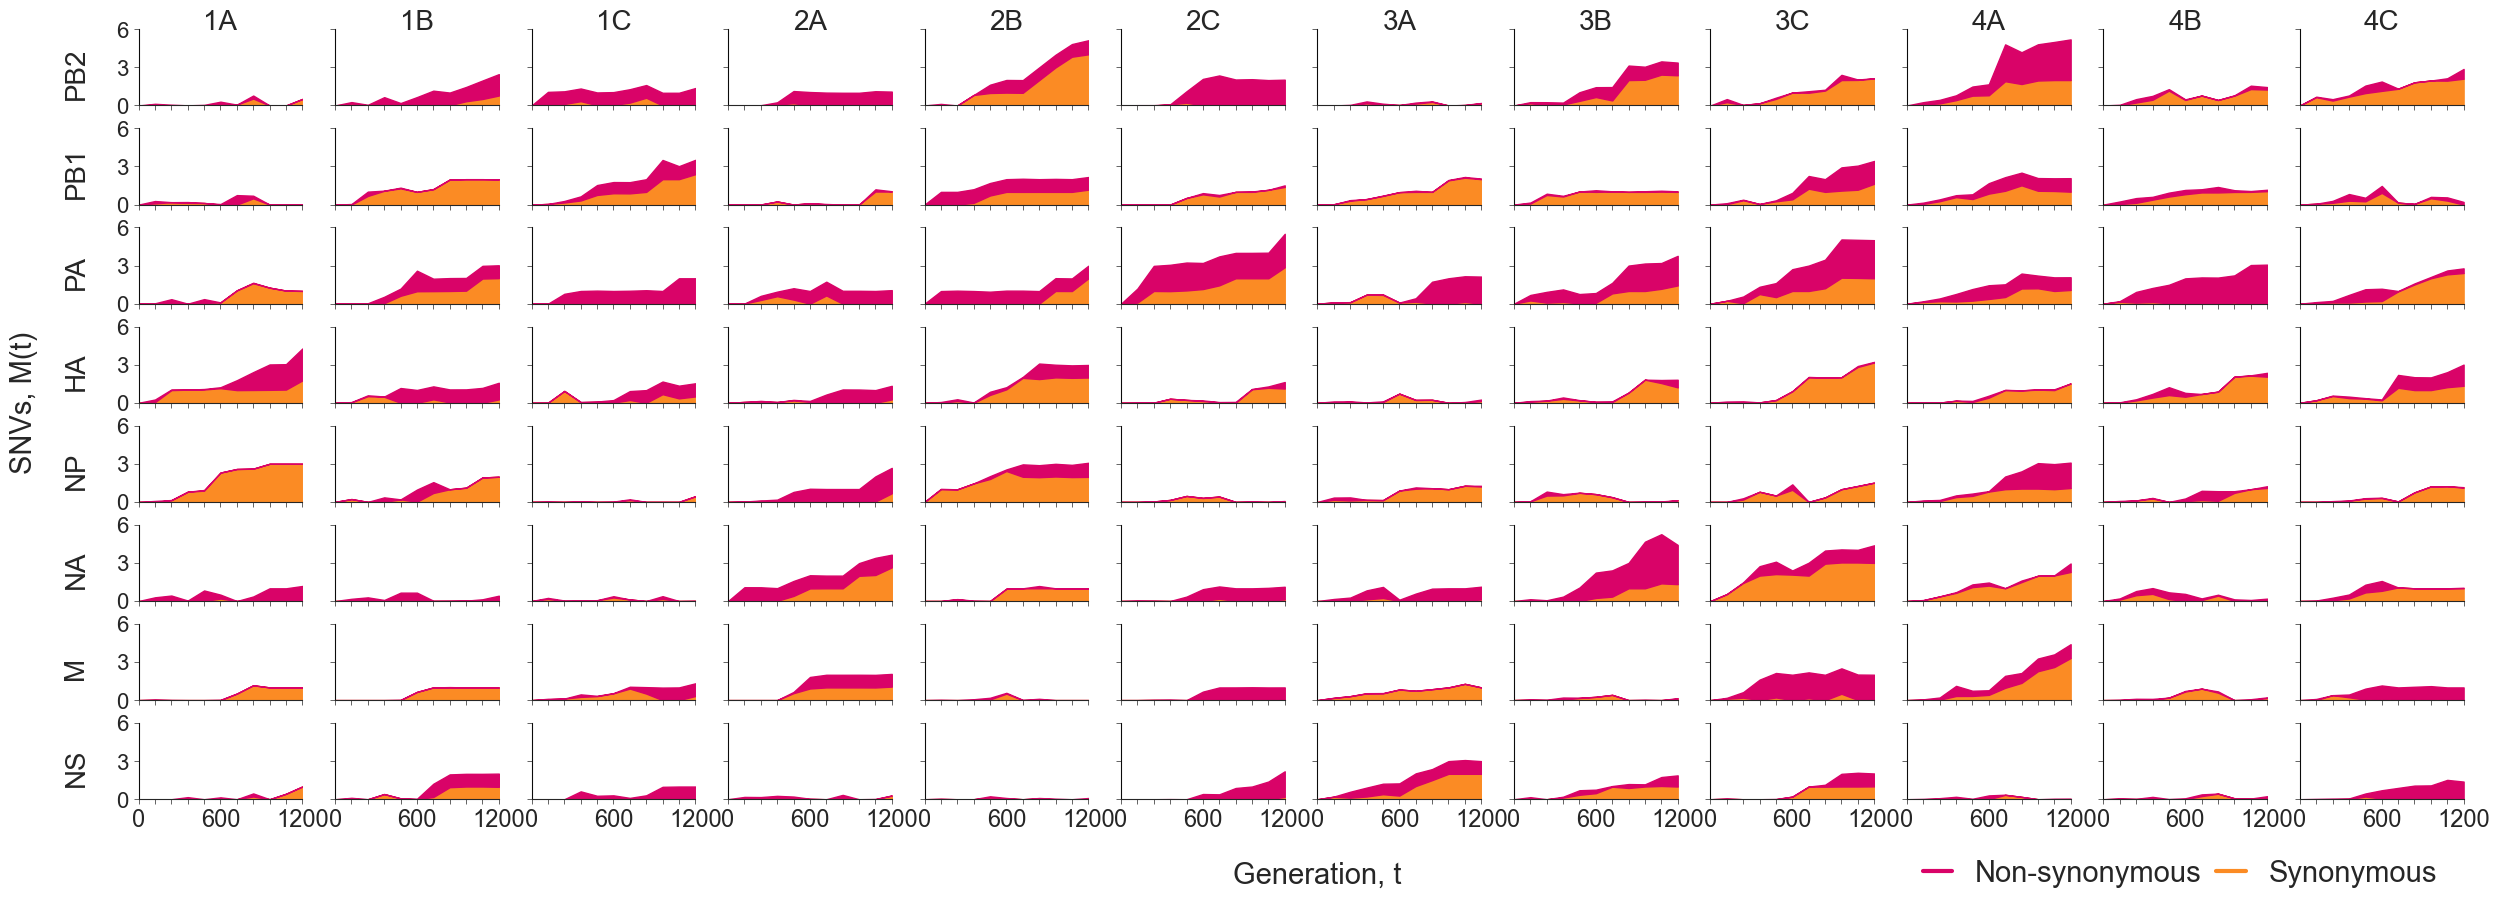

In [13]:
fig = plt.figure(figsize=(12*2.5, 8*1.25))

gs = gridspec.GridSpec(1,1, wspace=0.25, hspace=0.2, )

legend_elements = []#[Line2D([0], [0], color='white', label="population", linewidth=0,)]
for color, label in zip([nonsyn_color, syn_color], 
                        ["Non-synonymous", "synonymous", ]):
    legend_elements.append(Line2D([0], [0], color=color, label=label.capitalize(), linewidth=3,  ))

gsi = gridspec.GridSpecFromSubplotSpec(1,len(populations), subplot_spec=gs[-1], hspace=0.4, wspace=0.2)
for i, population in enumerate(populations):
    gsij = gridspec.GridSpecFromSubplotSpec(len(segments), 1, subplot_spec=gsi[i], wspace=0., hspace=0.3)
    df = accumulative_frequency[(accumulative_frequency["population"]==population)]
    
    for j, refname in enumerate(segments):
        ax = fig.add_subplot(gsij[j])
        syn_values = df[df["refname"]==refname]["accumulative syn freq"].dropna().tolist()
        ax.fill_between(passages, 0, syn_values, facecolor=syn_color, alpha=1, edgecolor=syn_color)
        
        nonsyn_values = df[df["refname"]==refname]["accumulative nonsyn freq"].dropna().tolist()
        ax.fill_between(passages, syn_values, [v+syn_values[k] for k, v in enumerate(nonsyn_values)], 
                        facecolor=nonsyn_color, alpha=1, edgecolor=nonsyn_color)
        
        ax.set_ylim(0,6)
        
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlim(-0, passages[-1])
        ax.axvline(0, color="black", zorder=100, lw=0.5)
        ax.set_yticks([0, 3,6])
        if i>0:
            ax.set_yticklabels([])
        else:
            ax.set_yticklabels([0, 3,6], size=16)
          
        if i == 0:
            ax.text(-30, 2.5, refname.split("-")[-1], rotation=90, va="center", ha="right", size=20)
        if j == 0:
            ax.text(50, 5.5, population, va="bottom", ha="center", size=20)
            
            
        ax.set_xticks(passages)
        if j == len(segments) -1:
            ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p%50==0 else "" for p in passages], size=17)
            if i == 6:
                ax.text(0, -6, "Generation, t",  va="center", ha="center", size=21)
                
        else:
            ax.set_xticklabels([])
        if i == 0 and j == 3:
            ax.text(-70, 0, "SNVs, M(t)", rotation=90, va="center", ha="center",  size=21)
        
        if j == 7 and i == 11:
            ax.legend(handles=legend_elements, loc='lower right',  
                                bbox_to_anchor=(1,-1.5), ncols =2, fontsize=21, handlelength=1, edgecolor=None, frameon=False, 
                                columnspacing=0.5)
    

### 1.4. Summary figure 

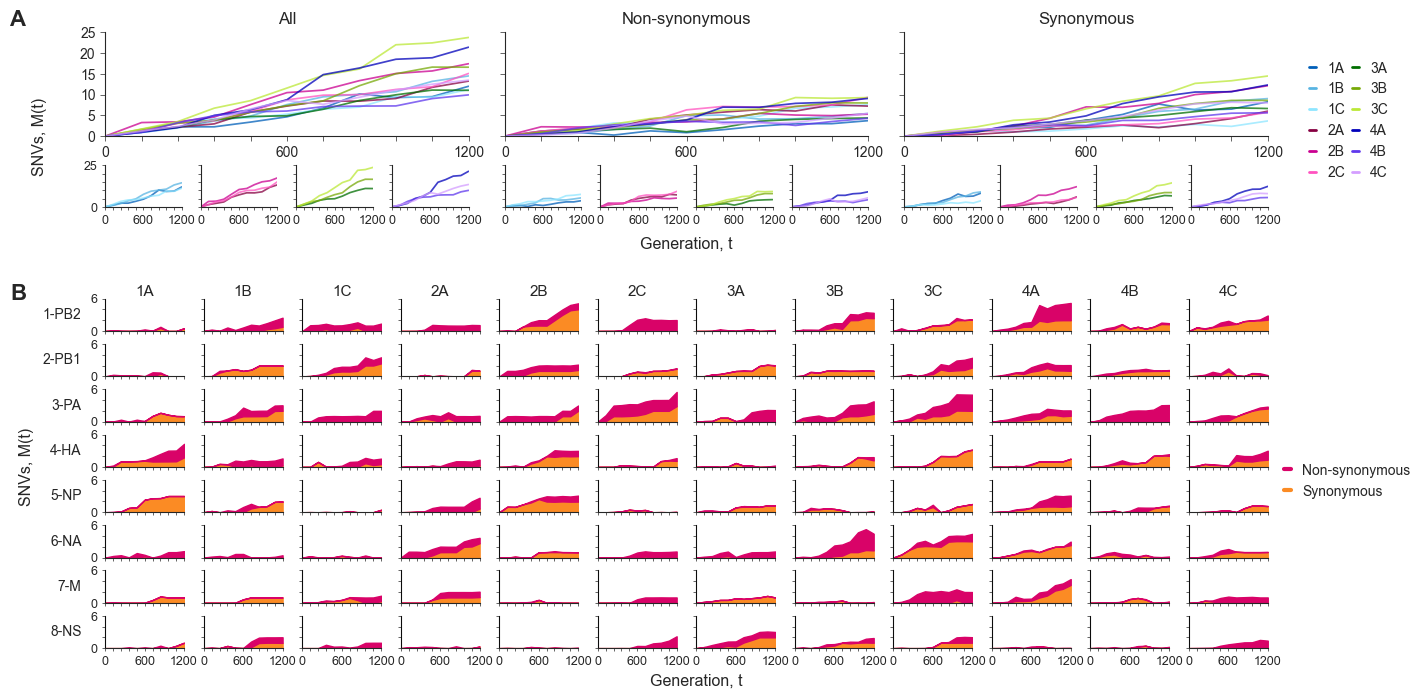

In [14]:
fig = plt.figure(figsize=(15,8))

gs = gridspec.GridSpec(2,1, wspace=0.25, hspace=0.35, height_ratios=[3,6])

gsi = gridspec.GridSpecFromSubplotSpec(2,1,  subplot_spec=gs[0], wspace=0.25, hspace=0.4, height_ratios=[2.5,1])
gsij = gridspec.GridSpecFromSubplotSpec(1,3, subplot_spec=gsi[0], hspace=0.3, wspace=0.1)

all_ax = fig.add_subplot(gsij[0])
nonsyn_ax = fig.add_subplot(gsij[1])
syn_ax = fig.add_subplot(gsij[2])

gsij = gridspec.GridSpecFromSubplotSpec(1,3, subplot_spec=gsi[1], hspace=0.3, wspace=0.1)
gsij0 = gridspec.GridSpecFromSubplotSpec(1,4, subplot_spec=gsij[0], hspace=0.3, wspace=0.25)
donor_all_axes = [fig.add_subplot(gsij0[0]), fig.add_subplot(gsij0[1]), fig.add_subplot(gsij0[2]), fig.add_subplot(gsij0[3])]
gsij1 = gridspec.GridSpecFromSubplotSpec(1,4, subplot_spec=gsij[1], hspace=0.3, wspace=0.25)
donor_nonsyn_axes = [fig.add_subplot(gsij1[0]), fig.add_subplot(gsij1[1]), fig.add_subplot(gsij1[2]), fig.add_subplot(gsij1[3])]
gsij2 = gridspec.GridSpecFromSubplotSpec(1,4, subplot_spec=gsij[2], hspace=0.3, wspace=0.25)
donor_syn_axes = [fig.add_subplot(gsij2[0]), fig.add_subplot(gsij2[1]), fig.add_subplot(gsij2[2]), fig.add_subplot(gsij2[3])]

for i, population in enumerate(populations):
    donor_idx = donors.index(int(population[0]))
    df = accumulative_frequency[(accumulative_frequency["population"]==population)&(accumulative_frequency["refname"]=="genome")]
    
    all_ax.plot(passages, df["accumulative freq"].tolist(), lw=1.25, alpha=0.75, color=population_cpal[i] )
    donor_all_axes[donor_idx].plot(passages, df["accumulative freq"].tolist(), lw=1.25, alpha=0.75, color=population_cpal[i] )
    
    nonsyn_ax.plot(passages, df["accumulative nonsyn freq"].tolist(), lw=1.25, alpha=0.75, color=population_cpal[i] )
    donor_nonsyn_axes[donor_idx].plot(passages, df["accumulative nonsyn freq"].tolist(), lw=1.25, alpha=0.75, color=population_cpal[i] )

    syn_ax.plot(passages, df["accumulative syn freq"].tolist(), lw=1.25, alpha=0.75, color=population_cpal[i] )
    donor_syn_axes[donor_idx].plot(passages, df["accumulative syn freq"].tolist(), lw=1.25, alpha=0.75, color=population_cpal[i] )
     
for ax in [all_ax, nonsyn_ax, syn_ax] + donor_all_axes + donor_nonsyn_axes + donor_syn_axes:
    ax.set_xlim(passages[0],passages[-1])
    ax.spines[['top','right']].set_visible(False)
    ax.set_ylim(0,25) 
    ax.set_yticks([0,5,10,15,20,25])
    ax.set_yticklabels([])
    ax.set_xticks(passages)
    ax.set_xticklabels([])
    
    
    ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p %50==0 else "" for p in passages])
    #ax.set_xlabel("Generation, t", size=11)
    
for ax in donor_all_axes + donor_nonsyn_axes + donor_syn_axes:
    ax.tick_params(length=2, axis="both")   
    
    ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p %50==0 else "" for p in passages], size=9)
      
all_ax.set_yticklabels([0,5,10,15,20,25])
donor_all_axes[0].set_yticklabels([0,"", "", "", "", 25], size=9)
all_ax.set_title("All", size=12)
nonsyn_ax.set_title("Non-synonymous", size=12)
syn_ax.set_title("Synonymous", size=12)
syn_ax.legend(handles=population_legend_elements, loc='center left',  bbox_to_anchor=(1.08,0.15), 
              ncols =2, fontsize=10, handlelength=0.5, edgecolor=None, frameon=False,  columnspacing=0.5)

nonsyn_ax.text(50, -27, "Generation, t", ha="center", size=11.5)
all_ax.text(-18, 0, "SNVs, M(t)", ha="center", va="center", size=11.5, rotation=90)
all_ax.text(-24, 28, "A", ha="center", va="center", size=16, fontweight="bold")


legend_elements = []#[Line2D([0], [0], color='white', label="population", linewidth=0,)]
for color, label in zip([nonsyn_color, syn_color], 
                        ["Non-synonymous", "synonymous", ]):
    legend_elements.append(Line2D([0], [0], color=color, label=label.capitalize(), linewidth=3,  ))


gsi = gridspec.GridSpecFromSubplotSpec(1,len(populations), subplot_spec=gs[-1], hspace=0., wspace=0.25)
for i, population in enumerate(populations):
    gsij = gridspec.GridSpecFromSubplotSpec(len(segments), 1, subplot_spec=gsi[i], wspace=0.2, hspace=0.4)
    df = accumulative_frequency[(accumulative_frequency["population"]==population)]
    
    for j, refname in enumerate(segments):
        ax = fig.add_subplot(gsij[j])
        syn_values = df[df["refname"]==refname]["accumulative syn freq"].dropna().tolist()
        ax.fill_between(passages, 0, syn_values, facecolor=syn_color, alpha=1, edgecolor=syn_color)
        
        nonsyn_values = df[df["refname"]==refname]["accumulative nonsyn freq"].dropna().tolist()
        ax.fill_between(passages, syn_values, [v+syn_values[k] for k, v in enumerate(nonsyn_values)], 
                        facecolor=nonsyn_color, alpha=1, edgecolor=nonsyn_color)
        
    
        ax.set_ylim(0,6)
        
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlim(-0, passages[-1])
        ax.axvline(0, color="black", zorder=100, lw=0.5)
        ax.set_yticks([0, 2,4,6])
        if i>0:
            ax.set_yticklabels([])
        else:
            ax.set_yticklabels([0, "", "",6], size=9)
          
        if i == 0:
            # ax.text(-30, 3, refname.split("-")[-1], rotation=90, va="center", ha="right", size=11)
            ax.text(-30, 3, refname, va="center", ha="right", size=10)
            
            if j == 0:
                ax.text(-100, 7, "B",  va="center", ha="right", size=16, fontweight="bold")

        if j == 0:
            ax.text(50, 6, population, va="bottom", ha="center", size=11)
            
        ax.tick_params(length=2, axis="both")   
        ax.set_xticks(passages)
        if j == len(segments) -1:
            ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p%50==0 else "" for p in passages], size=9)
            if i == 6:
                ax.text(0, -6, "Generation, t",  va="center", ha="center", size=11.5)
                
        else:
            ax.set_xticklabels([])
        if i == 0 and j == 3:
            ax.text(-100, 0, "SNVs, M(t)", rotation=90, va="center", ha="center",  size=11.5)
        
        if j == 3 and i == 11:
            ax.legend(handles=legend_elements, loc='upper left',  
                                bbox_to_anchor=(1.05, 0.5), ncols =1, fontsize=10, handlelength=0.5, edgecolor=None, frameon=False, 
                                columnspacing=0.5)

fig.savefig("../figures/fig2_total_derived_allele_frequency.svg", dpi=300,bbox_inches='tight')
fig.savefig("../figures/fig2_total_derived_allele_frequency.png", dpi=300,bbox_inches='tight')  

**Figure 2 The accumulation of SNVs over time, measured by total derived allele frequency M_p (t).** A, Accumulation of all, non-synonymous, and synonymous SNVs across the genome per population p. Top panels display all populations, whereas the lower panels display the accumulation SNVs over time per donor. B, Accumulation of synonymous and non-synonymous SNVs over time per population per segment.

### 1.5. Statistics PREP to compare rates


In [15]:
genome_df = accumulative_frequency[accumulative_frequency["refname"]=="genome"].drop(columns=["refname"]).reset_index(drop=True)
#mean centering passage
genome_df["passage_c"] =( genome_df["passage"] - np.mean(genome_df["passage"]))#/ np.std(genome_df["passage"])
genome_df = genome_df.rename(columns={c:c.replace(" ", "_") for c in genome_df.columns})
genome_df["donor"] = [int(p[0]) for p in genome_df["population"]]
genome_df["replicate"] = [p[-1] for p in genome_df["population"]]
genome_df["donor"] = genome_df["donor"].astype(str)
genome_df.to_csv("../results/genome_wide_accumulative_freq_over_time.csv", index=False)


In [16]:
df = accumulative_frequency[accumulative_frequency["refname"]!="genome"].reset_index(drop=True)
#mean centering passage
df["passage_c"] =(df["passage"] - np.mean(df["passage"]))#/ np.std(genome_df["passage"])
df = df.rename(columns={c:c.replace(" ", "_") for c in df.columns})
df["donor"] = [int(p[0]) for p in df["population"]]
df["replicate"] = [p[-1] for p in df["population"]]
df["donor"] = df["donor"].astype(str)

df.to_csv("../results/accumulative_freq_over_time_per_segment.csv", index="False")


### 1.6 STATISTICS TO COMPARE RATES DONE IN R NOTEBOOK


## 2. Nucleotide diversity

### 2.1. Calculate nucleotide diversity

In [17]:
nucleotide_diversity_df = []
df = trajectories.reset_index().melt(id_vars=["population", "refname", "nucpos", "snv"], value_name="frequency", var_name="passage" ).drop_duplicates().set_index(["population", "refname", "passage"]).sort_index()

nucleotide_diversity= []
for population in populations:
    #per segment
    for segment in segments:
        for passage in passages[1:]: #skipping passage zero
            try:
                sdf = df.loc[(population, segment, passage)]
            except:
                continue
            
            sdf = sdf[sdf["frequency"]>0]
            if len(sdf) == 0:
                continue

            all_allele_freqs = []
            sdf = sdf.set_index("nucpos")
            for nucpos in sdf.index.unique():
                ndf = sdf.loc[[nucpos]]
                
                allele_freqs= [1-ndf["frequency"].sum()] + ndf["frequency"].tolist() #add WT and sNV freqs
                all_allele_freqs.append(allele_freqs)

            #calculate pi
            try:
                
                pi = (1 - (np.array(all_allele_freqs, dtype=object)**2).sum(axis=1)).sum() / len(segment_nuc_cds[segment])
            except TypeError:
                
                max_length = max([len(l) for l in all_allele_freqs])
                updated_all_allele_freqs = []
                for i, l in enumerate(all_allele_freqs):
                    if len(l) != max_length:
                        updated_all_allele_freqs.append(l +[0.0])
                pi = (1 - (np.array(updated_all_allele_freqs)**2).sum(axis=1)).sum() / len(segment_nuc_cds[segment])
                
                
           
            nucleotide_diversity.append([population, segment, passage, pi], )
            
    #genome 
    for passage in passages[1:]: #skipping passage zero
        try:
            sdf = df.loc[(population)].reset_index().set_index(["passage"]).loc[passage]
        except:
            continue
        
            
        sdf = sdf[sdf["frequency"]>0]
        if len(sdf) == 0:
            continue
    
         
        all_allele_freqs = []
        sdf = sdf.set_index(["refname", "nucpos"])
        for (refname, nucpos) in sdf.index.unique():
            ndf = sdf.loc[[(refname, nucpos)]]
            
            allele_freqs= [1-ndf["frequency"].sum()] + ndf["frequency"].tolist() #add WT and sNV freqs
            all_allele_freqs.append(allele_freqs)

        #calculate pi 
        try:
            pi = (1 - (np.array(all_allele_freqs, dtype=object)**2).sum(axis=1)).sum() / len(segment_nuc_cds[segment])
        except TypeError:
            
            max_length = max([len(l) for l in all_allele_freqs])
            updated_all_allele_freqs = []
            for i, l in enumerate(all_allele_freqs):
                if len(l) != max_length:
                    updated_all_allele_freqs.append(l +[0.0])
            pi = (1 - (np.array(updated_all_allele_freqs)**2).sum(axis=1)).sum() / len(segment_nuc_cds[segment])

        nucleotide_diversity.append([population, "genome", passage, pi])

nucleotide_diversity = pd.DataFrame.from_records(nucleotide_diversity, columns=["population", "refname", "passage", "pi"])

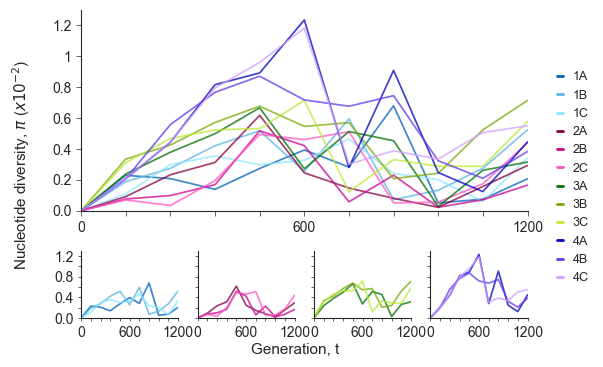

In [18]:

fig = plt.figure(figsize=(12,4))

gs = gridspec.GridSpec(1,2, wspace=0.5, hspace=0.5, width_ratios=[1.5,1])

gsi = gridspec.GridSpecFromSubplotSpec(2,1,  subplot_spec=gs[0], wspace=0.25, hspace=0.3, height_ratios=[3,1])
all_ax = fig.add_subplot(gsi[0])
gsij = gridspec.GridSpecFromSubplotSpec(1,4, subplot_spec=gsi[1], hspace=0.3, wspace=0.2)
donor_axes = [fig.add_subplot(gsij[0]), fig.add_subplot(gsij[1]), fig.add_subplot(gsij[2]), fig.add_subplot(gsij[3])]

df = nucleotide_diversity[nucleotide_diversity["refname"] == "genome"].pivot(index=["population"], columns="passage", values="pi")
df[0] = 0
df = df[passages]
for population, values in df.iterrows():
    all_ax.plot(passages, values.dropna().tolist(), c=population_cpal[populations.index(population)], lw=1.25, alpha=0.75,)
    dax = donor_axes[donors.index(int(population[0]))]
    dax.plot(passages, values.dropna().tolist(), c=population_cpal[populations.index(population)], lw=1.25, alpha=0.75,)
for ax in [all_ax] + donor_axes:
    ax.set_xlim(passages[0],passages[-1])
    ax.spines[['top','right']].set_visible(False)
    ax.set_xticks(passages)
    ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p%50==0 else "" for p in passages ])
    ax.set_ylim(0,0.8e-3)   
    ax.set_yticks([0., 2e-4, 4e-4, 6e-4, 8e-4])
    ax.set_ylim(0,1.3e-2)   
    ax.set_yticks([0., 2e-3, 4e-3, 6e-3, 8e-3, 1e-2, 1.2e-2])
    ax.set_yticklabels([])
    if ax in donor_axes:
        ax.tick_params(length=2)
        
    
all_ax.set_yticklabels([0., 0.2, 0.4, 0.6, 0.8, 1, 1.2])

donor_axes[0].set_yticklabels([0., '', 0.4, '', 0.8, '', 1.2])


all_ax.text(-13.5, 3e-3, "Nucleotide diversity, " + r"$\pi$ " + r"($x10^{-2}$)", size=11, rotation=90, ha="center", va="center")
# all_ax.text(-18, ax.get_ylim()[-1], "a", size=14, fontweight="bold")
donor_axes[1].text(100, -7e-3, "Generation, t", size=11, ha="center")

leg = all_ax.legend(handles=population_legend_elements, loc='upper left',  bbox_to_anchor=(1.04,0.75), ncols =1, fontsize=9, handlelength=0.5, edgecolor=None, frameon=False, columnspacing=0.5)

fig.savefig("../figures/figE3_nucleotide_diversity.svg", dpi=300,bbox_inches='tight')
fig.savefig("../figures/figE3_nucleotide_diversity.png", dpi=300,bbox_inches='tight')  

**Extended data Figure3 Genetic diversity over time measured by nucleotide diversity 𝜋.** Top panel shows all populations, whereas bottom panels are separated by donor. 

In [19]:
genome_df = nucleotide_diversity[nucleotide_diversity["refname"]=="genome"].copy().drop(columns=["refname"]).reset_index(drop=True)
#assuming no  denovo diversity in p0 
for population in populations:
    genome_df.loc[len(genome_df), :] = [population, 0, 0]
    
genome_df["donor"] = [int(p[0]) for p in genome_df["population"]]
genome_df["replicate"] = [p[-1] for p in genome_df["population"]]
genome_df["donor"] = genome_df["donor"].astype(str)
genome_df["pi_scaled"] = genome_df["pi"] * 1000

genome_df.to_csv("../results/genome_wide_nucleotide_diversity_over_time.csv", index=False)



### 2.2. Statistical differences
up until generation ~480  (passage 40) there sems to be a linear increase > determine if significant difference between donors

GO TO R NOTEBOOK

In [20]:
passage_cutoff = 40 #determined after visual inspection

In [21]:
genome_df = nucleotide_diversity[nucleotide_diversity["refname"]=="genome"].copy().drop(columns=["refname"]).reset_index(drop=True)
#assuming no  denovo diversity in p0 
for population in populations:
    genome_df.loc[len(genome_df), :] = [population, 0, 0]
genome_df = genome_df.sort_values(["population", "passage"], ignore_index=True)
#only including up to passage cutfoff
genome_df = genome_df[genome_df["passage"]<=passage_cutoff]
genome_df["donor"] = [int(p[0]) for p in genome_df["population"]]
genome_df["replicate"] = [p[-1] for p in genome_df["population"]]
genome_df["donor"] = genome_df["donor"].astype(str)
genome_df["pi_scaled"] = genome_df["pi"] * 1000 #scalling pi to try have better mixed model convergence > doesn't affect final results
timepoints = [p for p in passages if p <= passage_cutoff]


#mean centering passage
genome_df["passage_c"] =( genome_df["passage"] - np.mean(genome_df["passage"]))#/ np.std(genome_df["passage"])
genome_df["generation"] = [int((p*hours_per_passage)/generation_time) for p in genome_df["passage"]]
genome_df["generation_c"] =( genome_df["generation"] - np.mean(genome_df["generation"]))/ np.std(genome_df["generation"])


In [22]:
genome_df.to_csv("../results/genome_wide_nucleotide_diversity_over_first_40_passages.csv", index=False)